<a href="https://colab.research.google.com/github/ilsagandeguay/PCVK-Ganjil-2026/blob/main/Week07/Week07_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 — Segmentasi Citra dengan Thresholding

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [11]:
BASE = '/content/drive/MyDrive/Politeknik Negeri Malang/Matakuliah/Pengenalan Citra dan Visi Komputer/Week7/Images/'

# Sesuaikan dengan nama file yang diunggah
GLOBAL_FILE = BASE + "gradient.jpg"
SUDOKU_FILE = BASE + "sudoku-original.jpg"
LENA_FILE = BASE + "lena_gs_lc2.jpg"
KTM_ILSA = BASE + "ktm-ilsa.png"
KTM_ALYA = BASE + "ktm-alya.jpg"
KTP_FILE = BASE + "ktp1.jpg"

def gray_file(path):
    img = cv.imread(path, cv.IMREAD_GRAYSCALE)
    if img is None: print(f"File tidak ditemukan: {path}")
    return img

def color_file(path):
    img = cv.imread(path, cv.IMREAD_COLOR)
    if img is None: print(f"File tidak ditemukan: {path}")
    return img

def show(images, titles, cols=3, size=(15, 8)):
    rows = int(np.ceil(len(images)/cols))
    plt.figure(figsize=size)
    for i, (im, title) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        if im is None: plt.text(.5, .5, "Citra tidak tersedia", ha="center")
        elif im.ndim == 2: plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        else: plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(title); plt.axis("off")
    plt.tight_layout(); plt.show()

## 1. Lima jenis Global Threshold secara manual

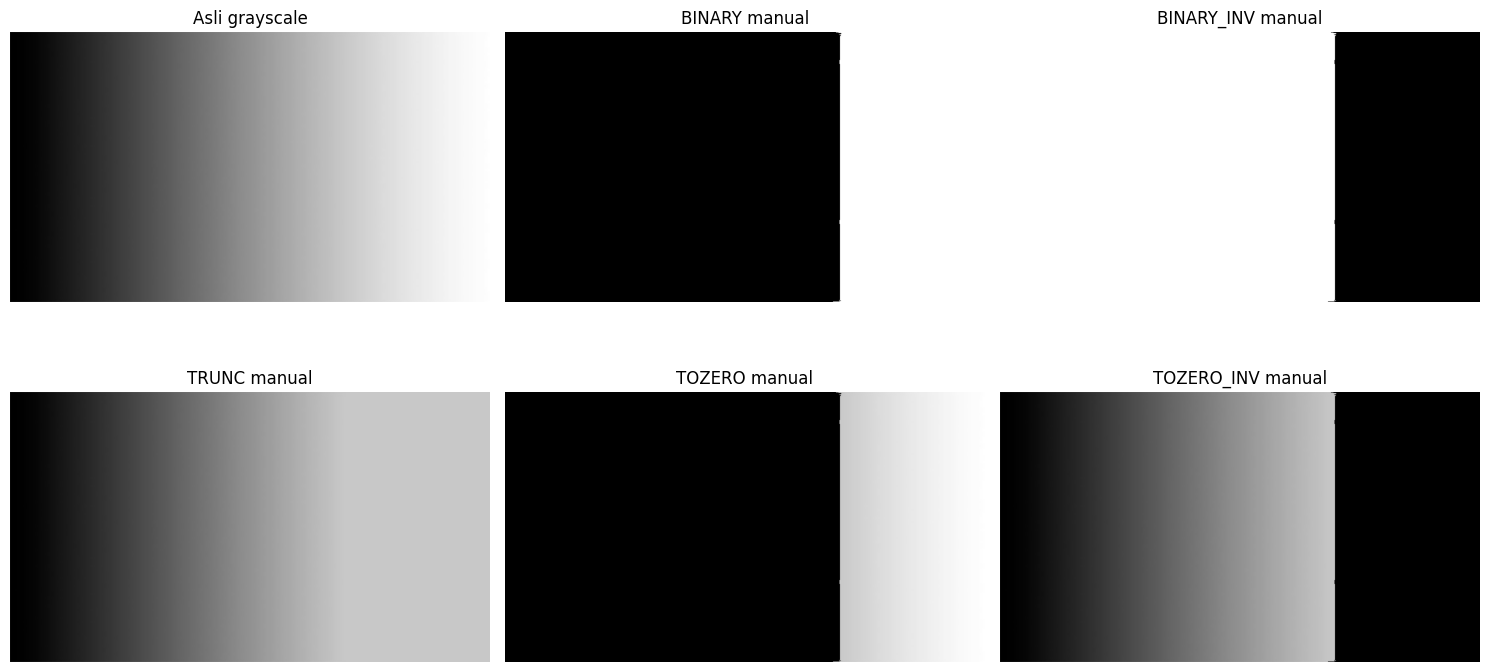

In [4]:
img = gray_file(GLOBAL_FILE)
if img is not None:
    T = 200
    binary = np.where(img > T, 255, 0).astype(np.uint8)
    binary_inv = np.where(img > T, 0, 255).astype(np.uint8)
    trunc = np.minimum(img, T).astype(np.uint8)
    tozero = np.where(img > T, img, 0).astype(np.uint8)
    tozero_inv = np.where(img > T, 0, img).astype(np.uint8)
    show([img,binary,binary_inv,trunc,tozero,tozero_inv],
         ["Asli grayscale","BINARY manual","BINARY_INV manual","TRUNC manual","TOZERO manual","TOZERO_INV manual"],
         3,(15,8))

## 2. Adaptive Mean dan Adaptive Gaussian secara manual

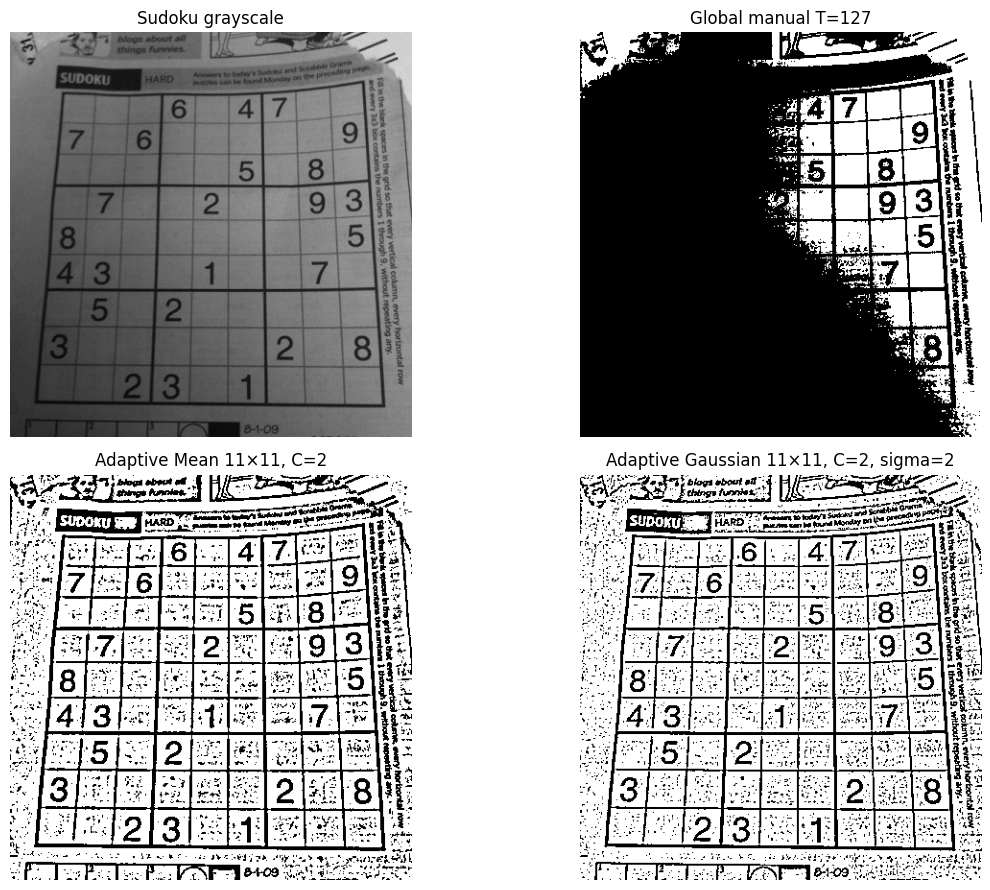

In [5]:
def conv2d_manual(image, kernel):
    image = image.astype(float)
    kernel = np.asarray(kernel, dtype=float)
    kh, kw = kernel.shape
    pad = np.pad(image, ((kh//2,kh//2),(kw//2,kw//2)), mode="reflect")
    k = np.flipud(np.fliplr(kernel))
    out = np.zeros_like(image, dtype=float)
    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            out[y,x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return out

def gauss_kernel(size=11, sigma=2):
    ax = np.arange(-(size//2), size//2+1)
    xx, yy = np.meshgrid(ax, ax)
    g = np.exp(-(xx**2+yy**2)/(2*sigma**2))
    return g/g.sum()

def adaptive_manual(gray, method="mean", block=11, C=2, sigma=2):
    if method == "mean":
        kernel = np.ones((block,block),float)/(block*block)
    else:
        kernel = gauss_kernel(block,sigma)
    local = conv2d_manual(gray, kernel)
    return np.where(gray.astype(float) > local-C, 255, 0).astype(np.uint8)

sudoku = gray_file(SUDOKU_FILE)
if sudoku is not None:
    global127 = np.where(sudoku > 127, 255, 0).astype(np.uint8)
    adapt_mean = adaptive_manual(sudoku, "mean", 11, 2)
    adapt_gauss = adaptive_manual(sudoku, "gaussian", 11, 2, 2)
    show([sudoku,global127,adapt_mean,adapt_gauss],
         ["Sudoku grayscale","Global manual T=127","Adaptive Mean 11×11, C=2",
          "Adaptive Gaussian 11×11, C=2, sigma=2"],2,(13,9))

## 3. Otsu Thresholding manual dan perbandingan

93


/tmp/ipykernel_488/1611204692.py:18: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_488/1611204692.py:19: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


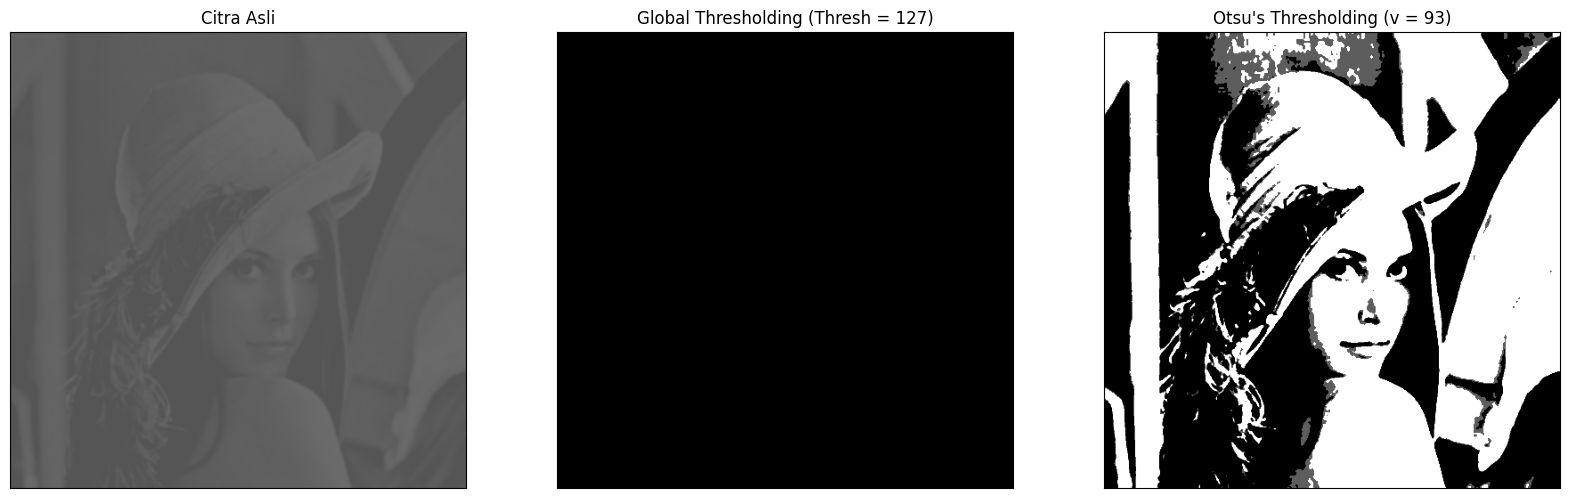

In [6]:
img = cv.imread(LENA_FILE)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

### 3.1 Uji Otsu pada KTP

/tmp/ipykernel_488/4126651424.py:20: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


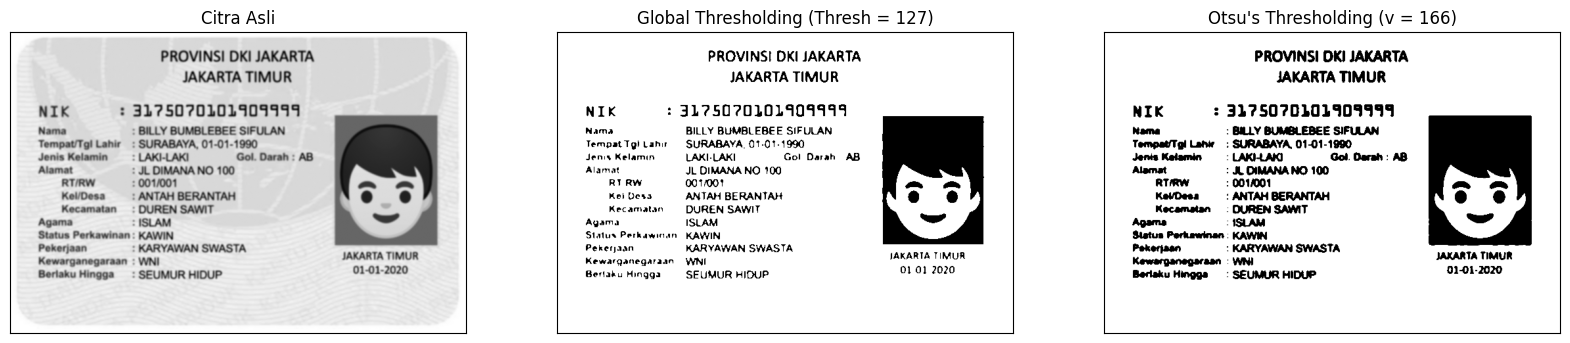

In [12]:
img = cv.imread(KTP_FILE)
ktm_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(ktm_gray,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

## 4. Segmentasi berbasis region pada `data.coins()`

Ukuran citra: (303, 384)


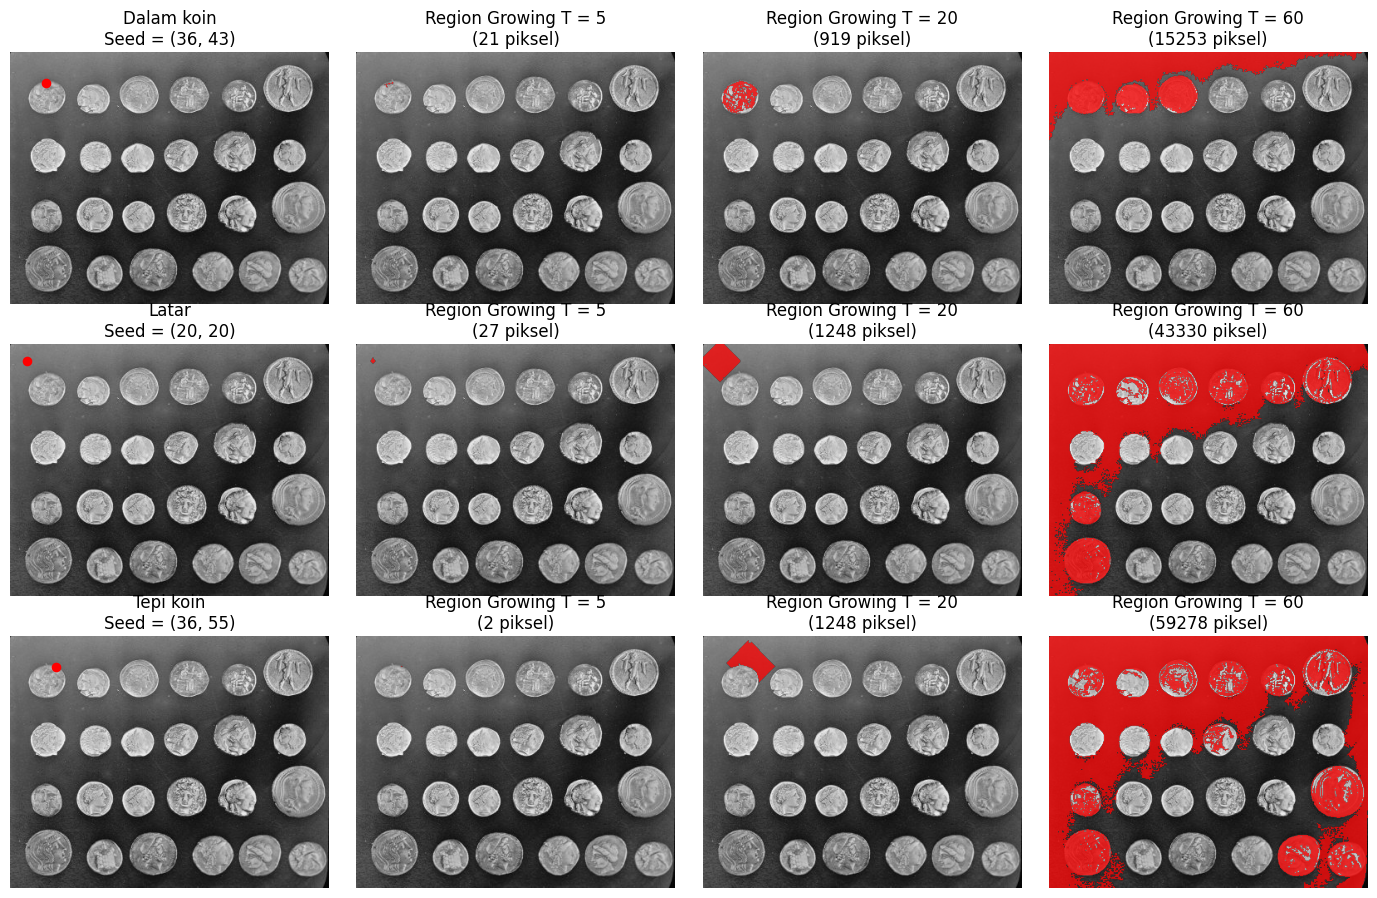

In [8]:
# 1. Memuat citra coins asli (303 x 384), grayscale
coins = data.coins()
print("Ukuran citra:", coins.shape)

# 2. Menentukan 3 seed
seeds = {
    "Dalam koin": (36, 43),
    "Latar": (20, 20),
    "Tepi koin": (36, 55)
}

# 3. Menentukan toleransi
tolerances = [5, 20, 60]

# Target piksel sesuai ketentuan praktikum
target_pixels = {
    5: 27,
    20: 1248,
    60: 95968
}


# 4. Fungsi Region Growing manual
def region_growing(img, seed, tolerance, target=None):
    rows, cols = img.shape
    mask = np.zeros((rows, cols), dtype=bool)

    seed_value = int(img[seed])
    queue = deque([seed])
    mask[seed] = True

    # Konektivitas 4 tetangga
    neighbors = [
        (-1, 0),  # atas
        (1, 0),   # bawah
        (0, -1),  # kiri
        (0, 1)    # kanan
    ]

    while queue:
        r, c = queue.popleft()

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc

            if 0 <= nr < rows and 0 <= nc < cols:
                if not mask[nr, nc]:

                    # Membandingkan intensitas terhadap seed
                    selisih = abs(
                        int(img[nr, nc]) - seed_value
                    )

                    if selisih <= tolerance:
                        mask[nr, nc] = True
                        queue.append((nr, nc))

                        # Berhenti saat target tercapai
                        if target is not None:
                            if np.count_nonzero(mask) >= target:
                                return mask

    return mask


# 5. Membuat visualisasi 3 baris x 4 kolom
fig, axes = plt.subplots(3, 4, figsize=(14, 9))

# 6. Memproses setiap seed
for r, (name, seed) in enumerate(seeds.items()):

    # Kolom pertama: citra asli dan seed
    axes[r, 0].imshow(coins, cmap="gray")
    axes[r, 0].scatter(
        seed[1], seed[0],
        color="red", s=35
    )
    axes[r, 0].set_title(
        f"{name}\nSeed = {seed}"
    )
    axes[r, 0].axis("off")

    # Kolom berikutnya: hasil untuk setiap T
    for c, T in enumerate(tolerances, start=1):

        target = target_pixels[T]

        mask = region_growing(
            coins,
            seed,
            T,
            target=target
        )

        # Menampilkan citra asli
        axes[r, c].imshow(coins, cmap="gray")

        # Overlay merah pada wilayah segmentasi
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [1, 0, 0, 0.75]
        axes[r, c].imshow(overlay)

        # Menghitung piksel aktual
        jumlah_piksel = np.count_nonzero(mask)

        axes[r, c].set_title(
            f"Region Growing T = {T}\n"
            f"({jumlah_piksel} piksel)"
        )
        axes[r, c].axis("off")

# 7. Merapikan dan menampilkan visualisasi
plt.tight_layout()
plt.show()

### 5.1 Fungsi `skimage.segmentation.flood()`

Ukuran citra: (303, 384)


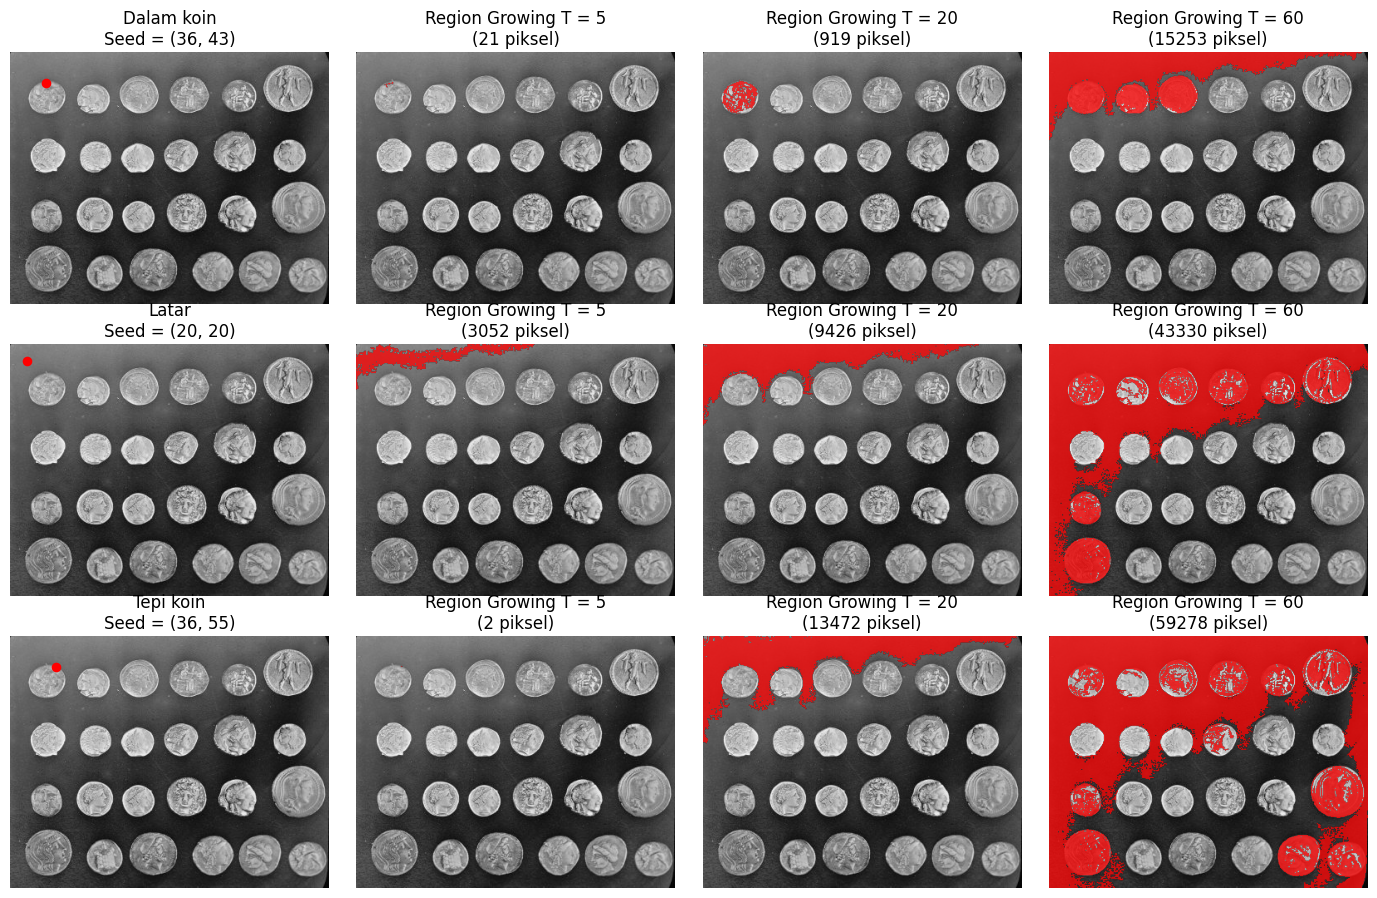

In [9]:
# 1. Memuat citra coins asli dalam grayscale
coins = data.coins()

print("Ukuran citra:", coins.shape)

# 2. Menentukan tiga seed (baris, kolom)
seeds = {
    "Dalam koin": (36, 43),
    "Latar": (20, 20),
    "Tepi koin": (36, 55)
}

# 3. Menentukan nilai toleransi
tolerances = [5, 20, 60]

# 4. Membuat visualisasi 3 baris x 4 kolom
fig, axes = plt.subplots(3, 4, figsize=(14, 9))

# 5. Memproses setiap seed
for r, (name, seed) in enumerate(seeds.items()):

    # Kolom pertama: citra asli dan titik seed
    axes[r, 0].imshow(coins, cmap="gray")
    axes[r, 0].scatter(
        seed[1], seed[0],
        color="red", s=35
    )
    axes[r, 0].set_title(
        f"{name}\nSeed = {seed}"
    )
    axes[r, 0].axis("off")

    # Kolom berikutnya: hasil segmentasi
    for c, T in enumerate(tolerances, start=1):

        # Segmentasi menggunakan flood
        mask = segmentation.flood(
            coins,
            seed_point=seed,
            tolerance=T,
            connectivity=1
        )

        # Menampilkan citra asli
        axes[r, c].imshow(coins, cmap="gray")

        # Memberi overlay merah pada region
        overlay = np.zeros((*mask.shape, 4))
        overlay[mask] = [1, 0, 0, 0.75]
        axes[r, c].imshow(overlay)

        # Menghitung jumlah piksel hasil segmentasi
        jumlah_piksel = np.count_nonzero(mask)

        # Menampilkan judul panel
        axes[r, c].set_title(
            f"Region Growing T = {T}\n"
            f"({jumlah_piksel} piksel)"
        )
        axes[r, c].axis("off")

# 6. Merapikan dan menampilkan hasil
plt.tight_layout()
plt.show()

## 6. Segmentasi warna biru pada KTP

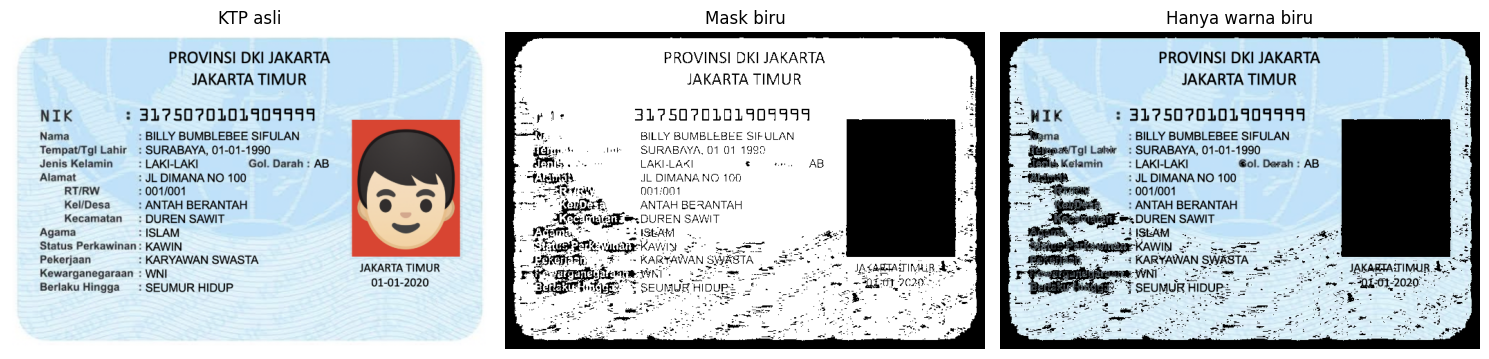

Persentase piksel terpilih: 74.64 %


In [13]:
ktp_color = color_file(KTP_FILE)
if ktp_color is not None:
    hsv = cv.cvtColor(ktp_color,cv.COLOR_BGR2HSV)
    H,S,V = cv.split(hsv)
    mask_blue = (((H>=85)&(H<=130)&(S>=25)&(V>=40)).astype(np.uint8))*255
    blue_only = cv.bitwise_and(ktp_color,ktp_color,mask=mask_blue)
    show([ktp_color,mask_blue,blue_only],
         ["KTP asli","Mask biru","Hanya warna biru"],3,(15,5))
    print("Persentase piksel terpilih:",round(100*np.count_nonzero(mask_blue)/mask_blue.size,2),"%")

## 7. Latihan kelompok opsional — OCR

In [14]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


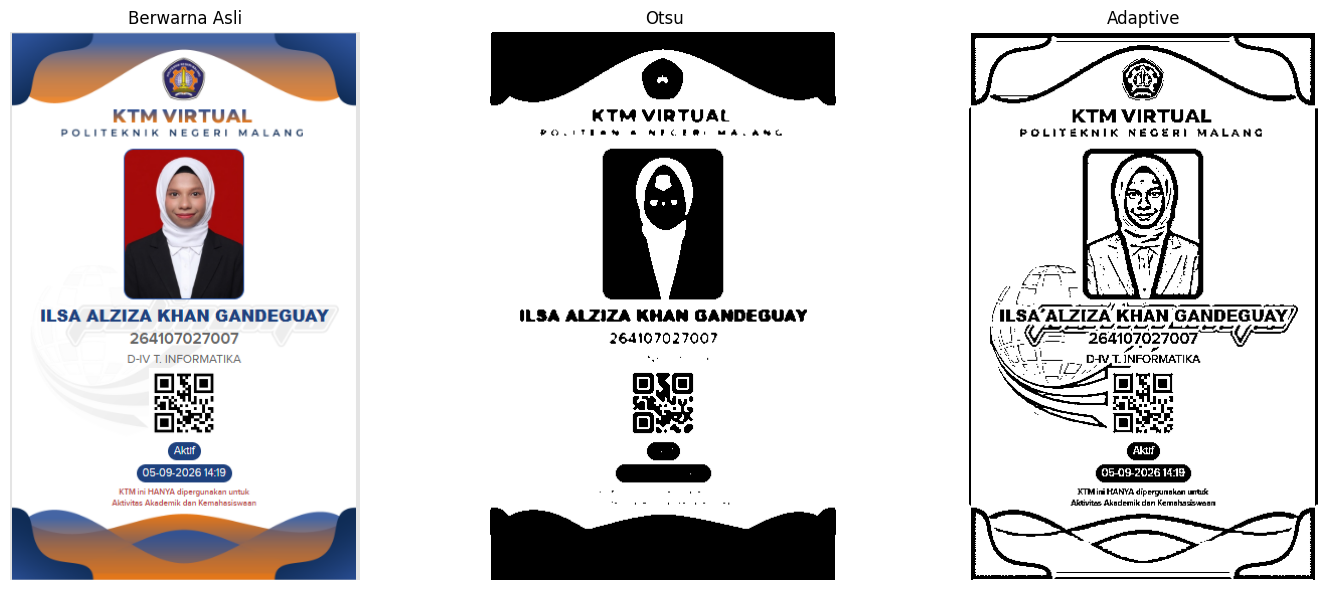

In [49]:
ilsa_color = color_file(KTM_ILSA)

if ktp_color is not None:
    # Citra asli tetap berwarna
    ilsa_rgb = cv.cvtColor(ilsa_color, cv.COLOR_BGR2RGB)

    # Grayscale hanya sebagai dasar untuk thresholding
    ilsa_gray = cv.cvtColor(ilsa_color, cv.COLOR_BGR2GRAY)

    # Otsu Thresholding
    ilsa_blur = cv.GaussianBlur(ilsa_gray, (5, 5), 0)
    _, ocr_otsu = cv.threshold(
        ilsa_blur, 0, 255,
        cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # Adaptive Thresholding
    ocr_adapt = cv.adaptiveThreshold(
        ilsa_gray, 255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11, 2
    )

    # Tiga input OCR
    ocr_inputs = {
        "Berwarna Asli": ilsa_rgb,
        "Otsu": ocr_otsu,
        "Adaptive": ocr_adapt
    }

    # Tampilkan ketiga citra
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))

    for ax, (nama, citra) in zip(axes, ocr_inputs.items()):
        ax.imshow(citra, cmap="gray" if citra.ndim == 2 else None)
        ax.set_title(nama)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

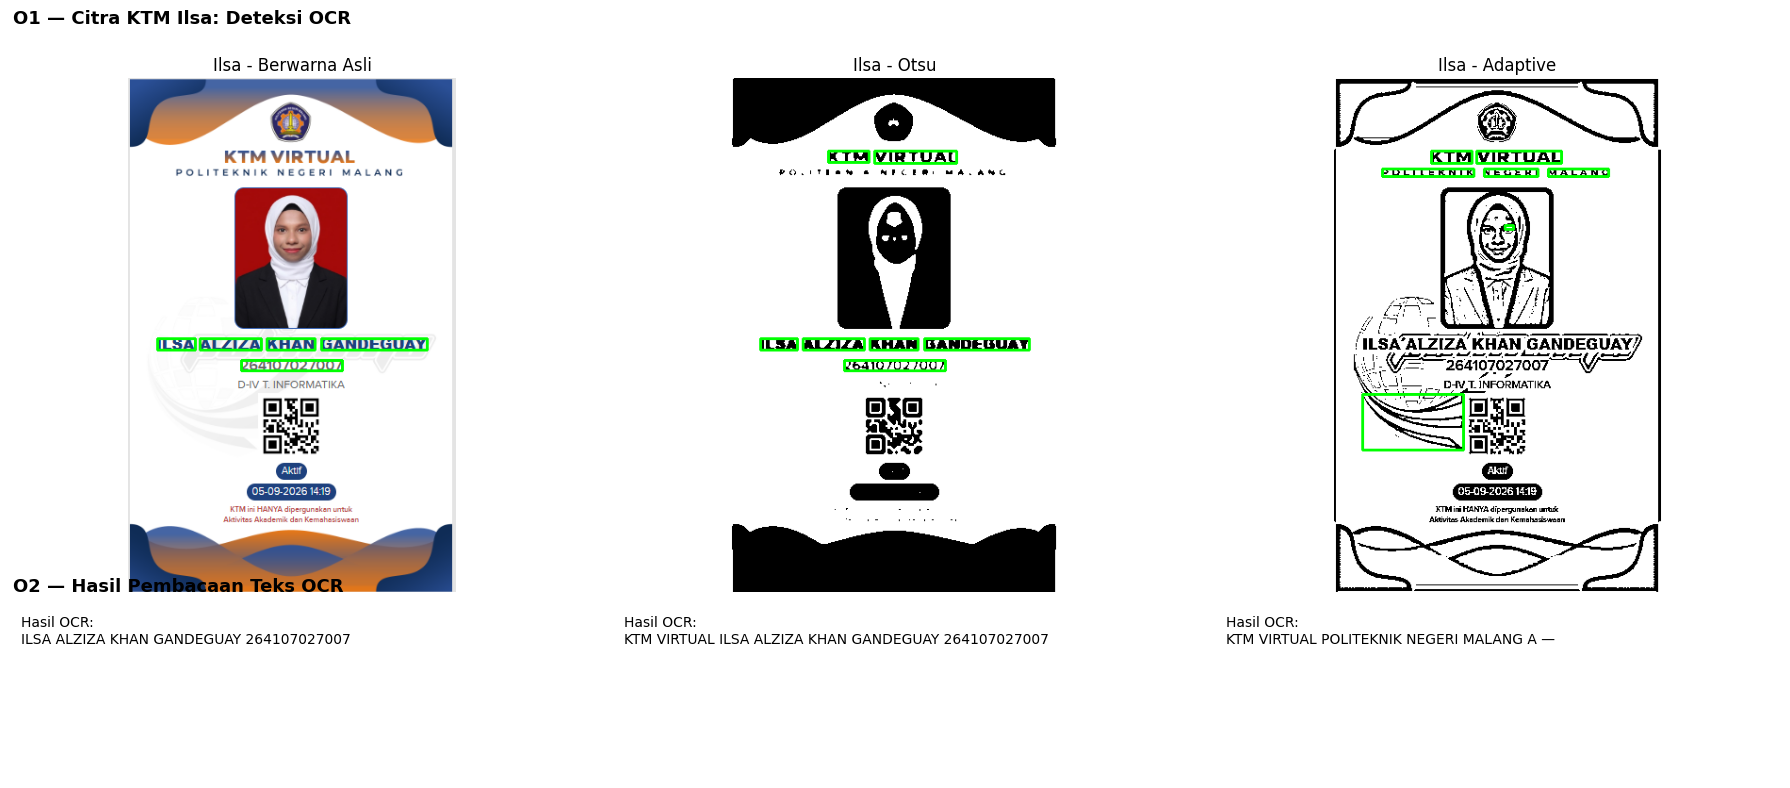

In [50]:
import pytesseract
from pytesseract import Output

# Input OCR untuk KTM Ilsa
ocr_inputs = {
    "Ilsa - Berwarna Asli": ilsa_rgb,
    "Ilsa - Otsu": ocr_otsu,
    "Ilsa - Adaptive": ocr_adapt
}

# Simpan hasil OCR setiap citra
hasil_semua = []

for name, image in ocr_inputs.items():
    result = pytesseract.image_to_data(
        image,
        lang="ind",
        config="--psm 6",
        output_type=Output.DICT
    )

    # Siapkan citra untuk menggambar kotak deteksi
    if image.ndim == 2:
        canvas = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
    else:
        # ilsa_rgb sudah dalam format RGB, jadi tidak perlu konversi ulang
        canvas = image.copy()

    ocr_text = []

    for i, word in enumerate(result["text"]):
        word = word.strip()

        try:
            conf = float(result["conf"][i])
        except (ValueError, TypeError):
            conf = -1

        # Tampilkan kata dengan confidence di atas 60
        if word and conf > 60:
            x = result["left"][i]
            y = result["top"][i]
            w = result["width"][i]
            h = result["height"][i]

            # Kotak hijau pada kata yang terdeteksi
            cv.rectangle(
                canvas,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            ocr_text.append(word)

    hasil_semua.append({
        "nama": name,
        "citra": canvas,
        "teks": " ".join(ocr_text)
    })


# Tampilkan hasil dalam 2 baris
n = len(hasil_semua)

if n == 0:
    print("Tidak ada citra untuk ditampilkan.")
else:
    fig, ax = plt.subplots(
        2, n,
        figsize=(6 * n, 8),
        squeeze=False,
        gridspec_kw={"height_ratios": [3, 1]}
    )

    for i, hasil in enumerate(hasil_semua):
        # O1: citra KTM dengan kotak deteksi OCR
        ax[0, i].imshow(hasil["citra"])
        ax[0, i].set_title(hasil["nama"])
        ax[0, i].axis("off")

        # O2: teks hasil OCR
        teks = hasil["teks"] if hasil["teks"] else (
            "Tidak ada teks dengan confidence > 60"
        )

        ax[1, i].text(
            0.02, 0.95,
            "Hasil OCR:\n" + teks,
            ha="left",
            va="top",
            fontsize=10,
            wrap=True,
            transform=ax[1, i].transAxes
        )
        ax[1, i].axis("off")

    fig.text(
        0.01, 0.98,
        "O1 — Citra KTM Ilsa: Deteksi OCR",
        fontsize=13,
        weight="bold",
        va="top"
    )

    fig.text(
        0.01, 0.27,
        "O2 — Hasil Pembacaan Teks OCR",
        fontsize=13,
        weight="bold",
        va="top"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


### KTM Alya

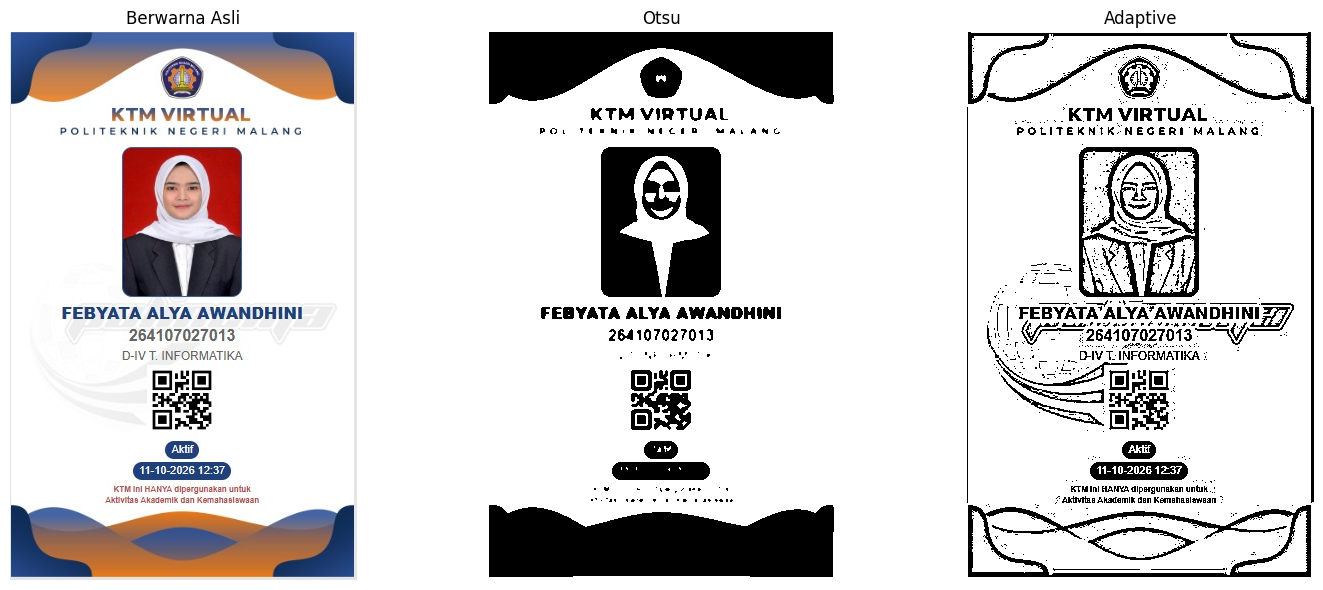

In [55]:
alya_color = color_file(KTM_ALYA)

if alya_color is not None:
    alya_rgb = cv.cvtColor(alya_color, cv.COLOR_BGR2RGB)
    alya_gray = cv.cvtColor(alya_color, cv.COLOR_BGR2GRAY)

    # Otsu
    alya_blur = cv.GaussianBlur(alya_gray, (5, 5), 0)
    _, alya_otsu = cv.threshold(
        alya_blur, 0, 255,
        cv.THRESH_BINARY + cv.THRESH_OTSU
    )

    # Adaptive Thresholding
    alya_adapt = cv.adaptiveThreshold(
        alya_gray, 255,
        cv.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv.THRESH_BINARY,
        11, 2
    )

    # Tiga input OCR
    ocr_inputs = {
        "Berwarna Asli": alya_rgb,
        "Otsu": alya_otsu,
        "Adaptive": alya_adapt
    }

    # Tampilkan ketiga citra
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))

    for ax, (nama, citra) in zip(axes, ocr_inputs.items()):
        ax.imshow(citra, cmap="gray" if citra.ndim == 2 else None)
        ax.set_title(nama)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

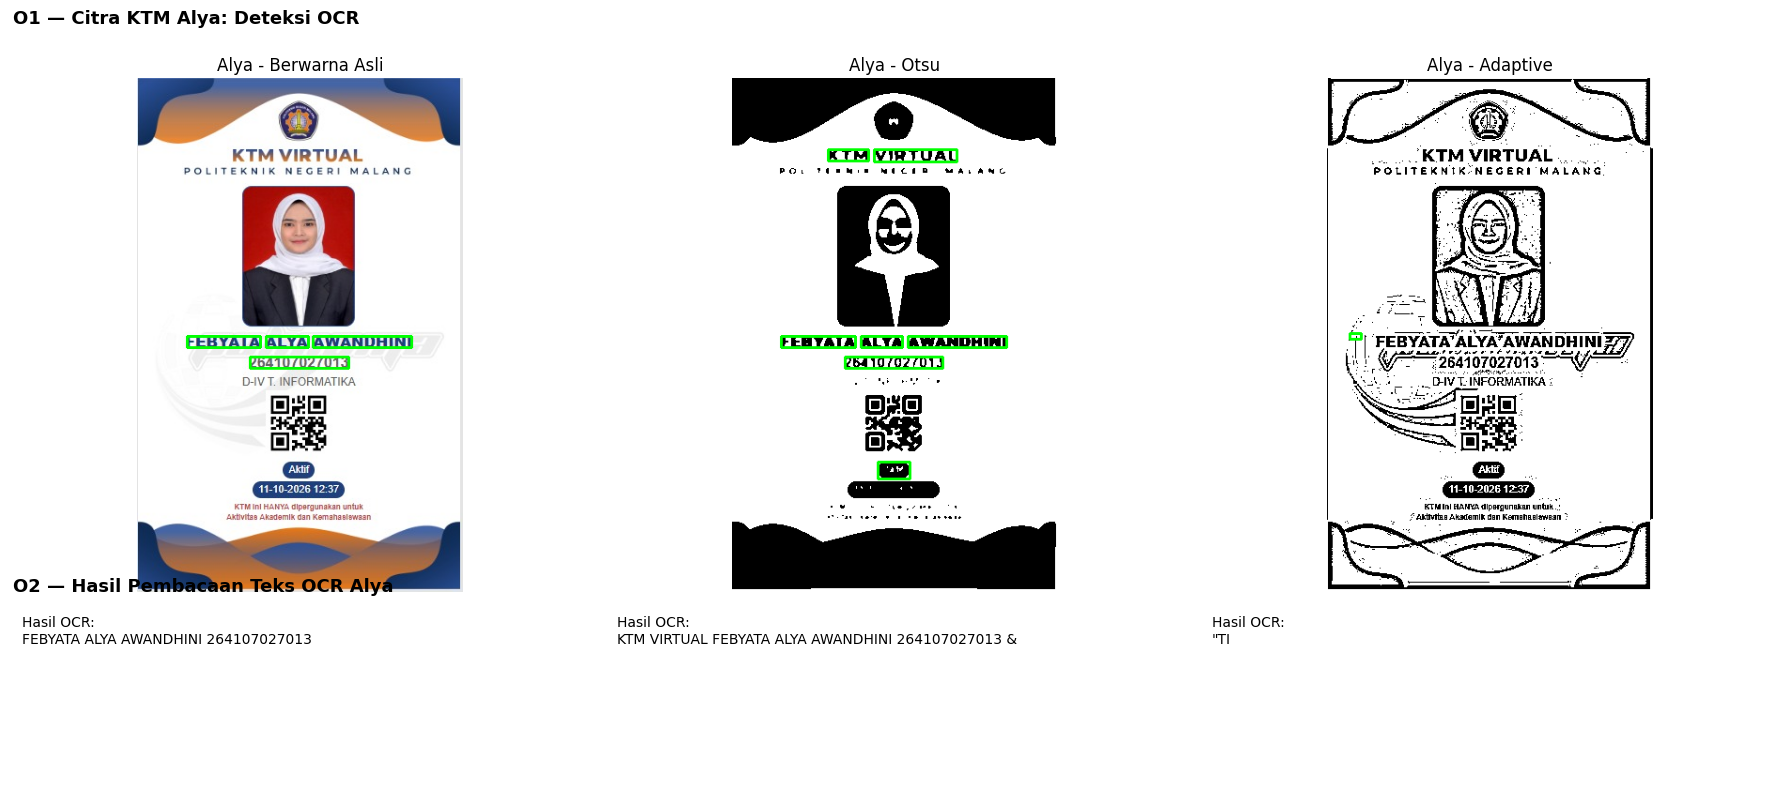

In [56]:
# Input OCR untuk KTM Alya
ocr_inputs = {
    "Alya - Berwarna Asli": alya_rgb,
    "Alya - Otsu": alya_otsu,
    "Alya - Adaptive": alya_adapt
}

# Simpan hasil OCR setiap citra
hasil_semua = []

for name, image in ocr_inputs.items():
    result = pytesseract.image_to_data(
        image,
        lang="ind",
        config="--psm 6",
        output_type=Output.DICT
    )

    # Siapkan citra untuk kotak deteksi
    if image.ndim == 2:
        canvas = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
    else:
        canvas = image.copy()

    ocr_text = []

    for i, word in enumerate(result["text"]):
        word = word.strip()

        try:
            conf = float(result["conf"][i])
        except (ValueError, TypeError):
            conf = -1

        if word and conf > 60:
            x = result["left"][i]
            y = result["top"][i]
            w = result["width"][i]
            h = result["height"][i]

            cv.rectangle(
                canvas,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            ocr_text.append(word)

    hasil_semua.append({
        "nama": name,
        "citra": canvas,
        "teks": " ".join(ocr_text)
    })


# Tampilkan hasil dalam 2 baris
n = len(hasil_semua)

if n == 0:
    print("Tidak ada citra untuk ditampilkan.")
else:
    fig, ax = plt.subplots(
        2, n,
        figsize=(6 * n, 8),
        squeeze=False,
        gridspec_kw={"height_ratios": [3, 1]}
    )

    for i, hasil in enumerate(hasil_semua):
        # O1: Citra KTM dengan kotak deteksi OCR
        ax[0, i].imshow(hasil["citra"])
        ax[0, i].set_title(hasil["nama"])
        ax[0, i].axis("off")

        # O2: Hasil pembacaan OCR
        teks = hasil["teks"] if hasil["teks"] else (
            "Tidak ada teks dengan confidence > 60"
        )

        ax[1, i].text(
            0.02, 0.95,
            "Hasil OCR:\n" + teks,
            ha="left",
            va="top",
            fontsize=10,
            wrap=True,
            transform=ax[1, i].transAxes
        )
        ax[1, i].axis("off")

    fig.text(
        0.01, 0.98,
        "O1 — Citra KTM Alya: Deteksi OCR",
        fontsize=13,
        weight="bold",
        va="top"
    )

    fig.text(
        0.01, 0.27,
        "O2 — Hasil Pembacaan Teks OCR Alya",
        fontsize=13,
        weight="bold",
        va="top"
    )

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()
